In [36]:
# Charger les bibliothèques de préparation des données et de tracé.
import pandas as pd
import matplotlib.pyplot as plt

# Nombre de décimales utilisé dans les appels à round(PRECISION).
# Les cellules qui écrivent directement round(2) ne dépendent pas de ce réglage.
PRECISION = 2

# Lire la feuille Orders du fichier Superstore disponible dans la sandbox.
df = pd.read_excel(
    "/workspace/data/sample_-_superstore.xls",
    sheet_name="Orders"
)

# Conserver le nom orders utilisé dans les questions du cours.
orders = df


### Question 01 · Fondamentaux

La part du chiffre d’affaires par région
Quelle proportion des ventes totales représente chaque région ?

Calculez la part du chiffre d’affaires de chaque région, en pourcentage.
Représentez les quatre parts avec un graphique à barres horizontales.
Vérifiez que la somme des parts est égale à 100 %, avant l’arrondi d’affichage.
À rendre : La formule, un tableau des parts, le graphique et une phrase de comparaison.

In [3]:
# Additionner Sales dans chaque région pour obtenir quatre totaux.
ventes = orders.groupby("Region")["Sales"].sum()

# ventes.sum() correspond au chiffre d’affaires de toutes les régions réunies.


In [8]:
# Part régionale (%) = ventes de la région / ventes totales × 100.
# Arrondir à deux décimales, puis classer les parts par ordre croissant.
# La Series parts contient donc déjà des valeurs arrondies.
parts = (ventes / ventes.sum() * 100).round(2).sort_values()


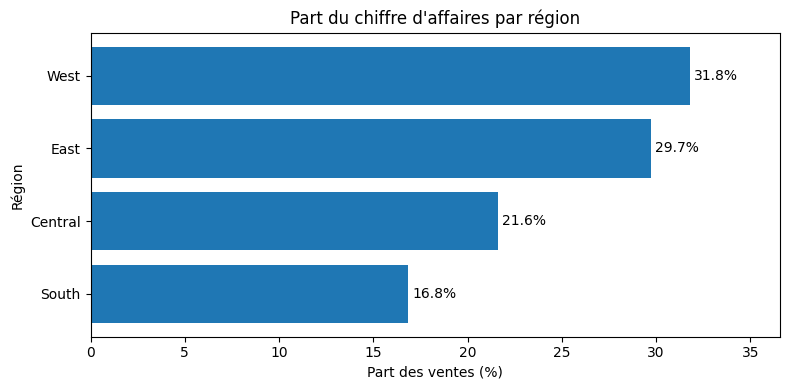

In [10]:
# Créer le graphique des parts, de la plus faible à la plus élevée.
fig, ax = plt.subplots(figsize=(8, 4))

# Les régions sont dans l’index ; les parts fixent la longueur des barres.
barres = ax.barh(parts.index, parts.values)

# Afficher une décimale et le symbole %, sans remultiplier les valeurs par 100.
ax.bar_label(barres, fmt="%.1f%%", padding=3)

# Préciser que les longueurs représentent des pourcentages de ventes.
ax.set(
    title="Part du chiffre d'affaires par région",
    xlabel="Part des ventes (%)",
    ylabel="Région"
)

# Éviter que les étiquettes en bout de barre soient coupées.
ax.margins(x=0.15)

plt.tight_layout()
plt.show()


In [12]:
# Afficher la somme des parts déjà arrondies dans la cellule précédente.
# Le format .0f masque les décimales : cet affichage ne vérifie donc pas
# l’égalité à 100 % des valeurs avant arrondi, demandée dans la consigne.
print(f"Somme des parts : {parts.sum():.0f} %")


Somme des parts : 100 %


### Exercice 02

Le taux de profit sur ventes
Quelle catégorie transforme le mieux son chiffre d’affaires en profit ?

Calculez les ventes totales, le profit total et le taux de profit sur ventes de chaque catégorie.
Comparez les trois taux avec un graphique à barres.
La catégorie qui vend le plus a-t-elle aussi le taux de profit sur ventes le plus élevé ? Justifiez votre réponse.
À rendre : La formule, un tableau par catégorie, le graphique et une réponse chiffrée.

In [14]:
# Additionner les ventes et les profits séparément dans chaque catégorie.
# Ces totaux serviront de base au taux de profit sur ventes.
bilan = orders.groupby("Category")[["Sales", "Profit"]].sum()


In [15]:
# Examiner les deux montants par catégorie avant de calculer leur rapport.
bilan


,Sales,Profit
Category,,
Furniture,754747.7613,19729.9956
Office Supplies,731893.3140,126023.4434
Technology,839893.2790,146543.3756


In [16]:
# Taux de profit sur ventes (%) = profit total / ventes totales × 100.
# On rapporte les sommes ; on ne fait pas la moyenne des taux de chaque ligne.
bilan["Taux (%)"] = ( bilan["Profit"] / bilan["Sales"] ) * 100


In [20]:
# Afficher les montants et le taux obtenu pour comparer les catégories.
# Ce ratio utilise le Profit fourni, sans décrire les coûts qui le composent.
bilan


0        2023
1        2023
2        2023
3        2023
4        2023
         ... 
10189    2026
10190    2026
10191    2026
10192    2026
10193    2026
Name: Order Date, Length: 10194, dtype: int32

### Question métier : de combien les ventes augmentent-elles ou diminuent-elles chaque année ?

$
\text{Évolution (\%)}=\frac{V_n-V_{n-1}}{V_{n-1}}\times100
$

In [44]:
# Extraire l’année, puis additionner les ventes dans chaque année.
orders["annee"] = orders["Order Date"].dt.year

ventes_annee = orders.groupby("annee")["Sales"].sum()

# pct_change calcule (valeur actuelle / valeur précédente) - 1.
# dropna retire la première année, sans référence ; × 100 exprime le taux en %.
ventes_annee.pct_change().dropna() * 100


annee
2024    -4.260216
2025    29.797595
2026    21.441074
Name: Sales, dtype: float64

### Le panier moyen
Quel est le montant moyen dépensé par commande dans chaque région ?

In [45]:
# Construire un bilan par région avec deux agrégations différentes.
bilan = orders.groupby("Region").agg(
    ventes = ("Sales", "sum"),           # Chiffre d’affaires de la région.
    commandes = ( "Order ID", "nunique" ) # Nombre de commandes distinctes.
)

# Panier moyen = ventes totales / nombre de commandes, puis arrondi d’affichage.
# Une commande peut avoir plusieurs lignes : leur nombre ne sert pas de diviseur.
bilan["panier_moyen"] = (bilan["ventes"] / bilan["commandes"]).round(PRECISION)


In [46]:
# Classer les régions du panier moyen le plus faible au plus élevé.
# sort_values renvoie ici un tableau trié sans modifier bilan en place.
bilan.sort_values("panier_moyen", ascending=True)


,ventes,commandes,panier_moyen
Region,,,
Central,503170.6728,1179,426.78
West,739813.6085,1635,452.49
East,691828.1680,1475,469.04
South,391721.9050,822,476.55


### Le taux de profit cumulé

Comment évolue le profit rapporté à l’ensemble des ventes accumulées au fil des années ?

Calculez, à la fin de chaque année, le taux de profit sur toutes les ventes accumulées depuis le début du fichier.

In [49]:
# Additionner ventes et profits par année ; groupby trie les années par défaut.
annuel = orders.groupby("annee")[["Sales", "Profit"]].sum()

# cumsum additionne chaque année aux précédentes depuis le début de la série.
# Les deux cumuls utilisent le même point de départ.
annuel["ventes_cumulees"] = annuel["Sales"].cumsum().round(PRECISION)
annuel["profits_cumulees"] = annuel["Profit"].cumsum().round(PRECISION)

# Taux cumulé = profits cumulés / ventes cumulées × 100.
# Ici, le ratio est arrondi avant la conversion en % : sa précision est réduite.
annuel["taux_cumule"] = (annuel["profits_cumulees"] / annuel["ventes_cumulees"] ).round(PRECISION) * 100

# Afficher le bilan annuel, les deux cumuls et leur taux.
annuel


,Sales,Profit,ventes_cumulees,profits_cumulees,taux_cumule
annee,,,,,
2023,494040.2121,51684.2957,494040.21,51684.30,10.0
2024,472993.0310,62020.9695,967033.24,113705.27,12.0
2025,613933.5800,82665.2018,1580966.82,196370.47,12.0
2026,745567.5312,95926.3476,2326534.35,292296.81,13.0


### La moyenne mobile
Comment lire la tendance générale des ventes en réduisant les fluctuations mensuelles ?

Calculez les ventes mensuelles, puis leur moyenne mobile sur trois mois.

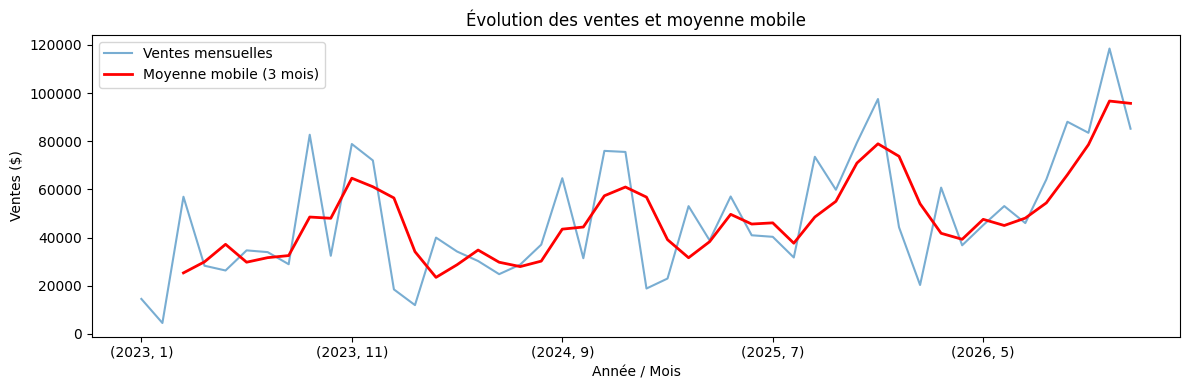

In [61]:
# Additionner les ventes pour chaque couple année-mois.
# Le résultat est une Series dont l’index possède deux niveaux : année et mois.
ventes_par_annee_mois = orders.groupby(
    ["annee", orders["Order Date"].dt.month]
)["Sales"].sum()

# Chaque moyenne porte sur trois lignes successives, avec la ligne courante.
# Cela correspond à trois mois si aucun mois ne manque dans la série.
# Les deux premières lignes n’ont pas encore une fenêtre complète.
moyenne_mobile = ventes_par_annee_mois.rolling(3).mean()

# Tracer les ventes mensuelles ; alpha rend cette première courbe plus claire.
# Le plot de Pandas crée ici une zone de tracé Matplotlib et la renvoie dans ax.
ax = ventes_par_annee_mois.plot(
    figsize=(12, 4),
    label="Ventes mensuelles",
    alpha=0.6
)

# Réutiliser ax pour superposer la moyenne mobile aux mêmes observations.
moyenne_mobile.plot(
    ax=ax,
    label="Moyenne mobile (3 mois)",
    color="red",
    linewidth=2
)

# Nommer les axes et distinguer les deux courbes grâce à la légende.
ax.set(
    title="Évolution des ventes et moyenne mobile",
    xlabel="Année / Mois",
    ylabel="Ventes ($)"
)

ax.legend()
plt.tight_layout()
plt.show()
